In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
data = pd.read_csv("/content/drive/MyDrive/energydata_complete.csv")

In [3]:
#Install libraries
!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn

In [4]:
#Import all libraries
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import drive

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from tensorflow.keras.models import Sequential, Model

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Flatten,
    Conv1D,
    MaxPooling1D,
    LSTM,
    GRU,
    Bidirectional,
    MultiHeadAttention,
    LayerNormalization,
    GlobalAveragePooling1D,
    Embedding,
    Add
)

from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
#Load our uploaded dataset
data = pd.read_csv(
    "/content/drive/MyDrive/energydata_complete.csv"
)

print("Dataset loaded successfully!")

print("Dataset shape:", data.shape)

display(data.head())

Dataset loaded successfully!
Dataset shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [6]:
#Explore dataset
print("Number of records:", len(data))

print("Number of columns:", len(data.columns))

print("\nColumn names:")

print(data.columns.tolist())

print("\nDataset information:")

data.info()

print("\nMissing values:")

print(data.isnull().sum())

print("\nStatistical summary:")

display(data.describe())


Number of records: 19735
Number of columns: 29

Column names:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5       

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,...,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,...,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,...,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,...,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,...,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,...,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,...,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,...,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


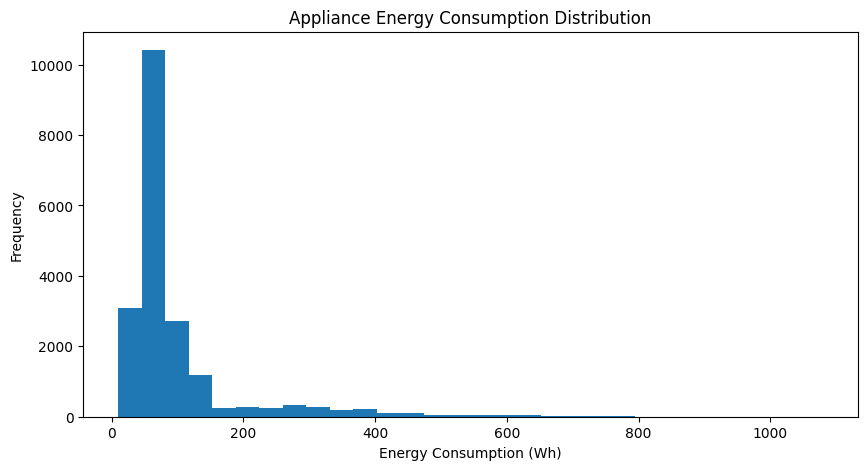

In [7]:
#Check target variable
plt.figure(figsize=(10, 5))

plt.hist(data['Appliances'], bins=30)

plt.title("Appliance Energy Consumption Distribution")

plt.xlabel("Energy Consumption (Wh)")

plt.ylabel("Frequency")

plt.show()


In [8]:
#Data preprocessing
# Convert date column

data['date'] = pd.to_datetime(data['date'])

# Sort dataset by date

data = data.sort_values(
    'date'
).reset_index(drop=True)

# Extract hour and day

data['hour'] = data['date'].dt.hour

data['day_of_week'] = data['date'].dt.dayofweek

# Create cyclical time features

data['hour_sin'] = np.sin(
    2 * np.pi * data['hour'] / 24
)

data['hour_cos'] = np.cos(
    2 * np.pi * data['hour'] / 24
)

data['day_sin'] = np.sin(
    2 * np.pi * data['day_of_week'] / 7
)

data['day_cos'] = np.cos(
    2 * np.pi * data['day_of_week'] / 7
)

# Remove unnecessary columns

data = data.drop(
    columns=[
        'date',
        'hour',
        'day_of_week',
        'rv1',
        'rv2'
    ],
    errors='ignore'
)

# Handle missing values

data = data.dropna().reset_index(drop=True)

print("Data preprocessing completed!")

print("New dataset shape:", data.shape)

display(data.head())

Data preprocessing completed!
New dataset shape: (19735, 30)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour_sin,hour_cos,day_sin,day_cos
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,6.600000,733.5,92.0,7.000000,63.000000,5.3,-0.965926,-0.258819,0.0,1.0
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,6.483333,733.6,92.0,6.666667,59.166667,5.2,-0.965926,-0.258819,0.0,1.0
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,6.366667,733.7,92.0,6.333333,55.333333,5.1,-0.965926,-0.258819,0.0,1.0
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,6.250000,733.8,92.0,6.000000,51.500000,5.0,-0.965926,-0.258819,0.0,1.0
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,6.133333,733.9,92.0,5.666667,47.666667,4.9,-0.965926,-0.258819,0.0,1.0


In [9]:
#Separate input and target variables
TARGET = 'Appliances'

X = data.drop(
    columns=[TARGET]
).values

y = data[TARGET].values.reshape(-1, 1)

print("Input features shape:", X.shape)

print("Target shape:", y.shape)

print("Target variable:", TARGET)

Input features shape: (19735, 29)
Target shape: (19735, 1)
Target variable: Appliances


In [10]:
#Split dataset
n = len(X)

train_end = int(n * 0.70)

val_end = int(n * 0.85)

print("Total records:", n)

print("Training records:", train_end)

print("Validation records:", val_end - train_end)

print("Testing records:", n - val_end)

Total records: 19735
Training records: 13814
Validation records: 2960
Testing records: 2961


In [11]:
#Feature scaling
# Re-extract X and y to make sure they are aligned with the preprocessed 'data' DataFrame
TARGET = 'Appliances'

# Ensure we only use numeric columns from the processed dataset
numeric_cols = data.select_dtypes(include=[np.number]).columns
features = [col for col in numeric_cols if col != TARGET]

X = data[features].values
y = data[TARGET].values.reshape(-1, 1)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

# Fit only on training data
x_scaler.fit(X[:train_end])
y_scaler.fit(y[:train_end])

# Transform features
X_scaled = x_scaler.transform(X)
y_scaled = y_scaler.transform(y)

print("Feature scaling completed!")

Feature scaling completed!


In [12]:
#Create time-series sequences

LOOKBACK = 6
# Combine input features and previous appliance readings

all_features = np.concatenate(
    [X_scaled, y_scaled],
    axis=1
)

X_sequences = []

y_sequences = []

target_indices = []

for i in range(LOOKBACK, len(data)):

    X_sequences.append(
        all_features[i-LOOKBACK:i]
    )

    y_sequences.append(
        y_scaled[i]
    )

    target_indices.append(i)

X_sequences = np.array(X_sequences)

y_sequences = np.array(y_sequences)

target_indices = np.array(target_indices)

print("Sequence creation completed!")

print("X shape:", X_sequences.shape)

print("Y shape:", y_sequences.shape)

Sequence creation completed!
X shape: (19729, 6, 30)
Y shape: (19729, 1)


In [13]:
#Divide sequences into training, validation and testing

train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train = X_sequences[train_mask]

y_train = y_sequences[train_mask]

X_val = X_sequences[val_mask]

y_val = y_sequences[val_mask]

X_test = X_sequences[test_mask]

y_test = y_sequences[test_mask]

print("Training:", X_train.shape)

print("Validation:", X_val.shape)

print("Testing:", X_test.shape)

Training: (13808, 6, 30)
Validation: (2960, 6, 30)
Testing: (2961, 6, 30)


In [14]:
#Build eight deep learning models
#ANN model(Artificial Neural Network)

def build_ann(shape):

    model = Sequential([
        Input(shape=shape),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model


In [15]:
#DNN model(Deep Neural Network)

def build_dnn(shape):

    model = Sequential([
        Input(shape=shape),
        Flatten(),
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model


In [16]:
#CNN model(Convolutional Neural Network)

def build_cnn(shape):

    model = Sequential([
        Input(shape=shape),

        Conv1D(
            64, 2,
            activation='relu'
        ),

        Conv1D(
            128, 2,
            activation='relu'
        ),

        MaxPooling1D(2),

        Flatten(),

        Dense(64, activation='relu'),

        Dropout(0.2),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [17]:
#LSTM model(learns sequential patterns)

def build_lstm(shape):

    model = Sequential([
        Input(shape=shape),

        LSTM(64, return_sequences=True),

        Dropout(0.2),

        LSTM(32),

        Dense(32, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [18]:
#GRU model (uses update and reset gates)
def build_gru(shape):

    model = Sequential([
        Input(shape=shape),

        GRU(64, return_sequences=True),

        Dropout(0.2),

        GRU(32),

        Dense(32, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [19]:
#BiLSTM model(processes sequences in two directions)

def build_bilstm(shape):

    model = Sequential([
        Input(shape=shape),

        Bidirectional(
            LSTM(64, return_sequences=True)
        ),

        Dropout(0.2),

        Bidirectional(LSTM(32)),

        Dense(32, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [20]:
#CNN-LSTM model(Combines CNN and LSTM)

def build_cnn_lstm(shape):

    model = Sequential([
        Input(shape=shape),

        Conv1D(
            64,
            kernel_size=2,
            activation='relu',
            padding='causal'
        ),

        MaxPooling1D(2),

        LSTM(64),

        Dropout(0.2),

        Dense(32, activation='relu'),

        Dense(1)
    ])

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [21]:
#Transformer model(An attention-based deep learning architecture)

def build_transformer(shape):

    inputs = Input(shape=shape)

    x = Dense(64)(inputs)

    # Positional embedding

    positions = tf.range(
        start=0,
        limit=shape[0]
    )

    position_embedding = Embedding(
        input_dim=shape[0],
        output_dim=64
    )(positions)

    x = x + position_embedding

    # Multi-head attention

    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=16
    )(x, x)

    x = Add()([x, attention])

    x = LayerNormalization()(x)

    # Feed-forward network

    ff = Dense(
        128,
        activation='relu'
    )(x)

    ff = Dense(64)(ff)

    x = Add()([x, ff])

    x = LayerNormalization()(x)

    x = GlobalAveragePooling1D()(x)

    x = Dense(
        32,
        activation='relu'
    )(x)

    outputs = Dense(1)(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )

    return model

In [22]:
#Train all diff 8 models with dataset

model_builders = {

    "ANN": build_ann,

    "DNN": build_dnn,

    "CNN": build_cnn,

    "LSTM": build_lstm,

    "GRU": build_gru,

    "BiLSTM": build_bilstm,

    "CNN-LSTM": build_cnn_lstm,

    "Transformer": build_transformer

}

trained_models = {}

histories = {}

for name, builder in model_builders.items():

    print("\n==========================")

    print("Training:", name)

    print("==========================")

    model = builder(X_train.shape[1:])

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    trained_models[name] = model

    histories[name] = history

    print(name, "completed!")

print("\nAll 8 models trained successfully!")


Training: ANN
Epoch 1/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.6618 - mae: 0.4569 - val_loss: 0.3899 - val_mae: 0.3088
Epoch 2/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4772 - mae: 0.3631 - val_loss: 0.3702 - val_mae: 0.2896
Epoch 3/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4399 - mae: 0.3417 - val_loss: 0.3782 - val_mae: 0.2709
Epoch 4/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4250 - mae: 0.3335 - val_loss: 0.3509 - val_mae: 0.2762
Epoch 5/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4061 - mae: 0.3242 - val_loss: 0.3461 - val_mae: 0.2814
Epoch 6/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3963 - mae: 0.3159 - val_loss: 0.3721 - val_mae: 0.3237
Epoch 7/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3920 - mae: 0.3152 - val_loss: 0.3409 - val_mae: 0.2682
Epoch 8/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3797 - mae: 0.3118 - val_loss: 0.3522 - val_mae: 0.2764
Epoch 9/10
216/216 ━━━━━━━━━━━━━━━━━━━━ 1

In [23]:
#Evaluate all eight models
#Select the best model using validation data

validation_results = []

val_actual = y_scaler.inverse_transform(
    y_val
).flatten()

for name, model in trained_models.items():

    val_pred_scaled = model.predict(
        X_val,
        verbose=0
    )

    val_predictions = y_scaler.inverse_transform(
        val_pred_scaled
    ).flatten()

    val_rmse = np.sqrt(
        mean_squared_error(
            val_actual,
            val_predictions
        )
    )

    validation_results.append({
        "Model": name,
        "Validation RMSE": val_rmse
    })

validation_df = pd.DataFrame(
    validation_results
).sort_values(
    by="Validation RMSE"
).reset_index(drop=True)

print("VALIDATION MODEL COMPARISON")

display(validation_df.round(4))

best_model_name = validation_df.iloc[0]["Model"]

print("Best Model Based on Validation RMSE:", best_model_name)

VALIDATION MODEL COMPARISON


,Model,Validation RMSE
0,GRU,58.7168
1,BiLSTM,59.4242
2,LSTM,59.7850
3,DNN,61.6770
4,CNN-LSTM,62.1116
5,ANN,62.2583
6,CNN,62.9439
7,Transformer,67.7805


Best Model Based on Validation RMSE: GRU


In [24]:
#Calculate all eight models' test metrics

regression_results = []

# Actual energy values in Wh
actual = y_scaler.inverse_transform(
    y_test
).flatten()

for name, model in trained_models.items():

    print("\nEvaluating:", name)

    # Predict values
    pred_scaled = model.predict(
        X_test,
        verbose=0
    )

    # Convert predictions into original Wh scale
    predictions = y_scaler.inverse_transform(
        pred_scaled
    ).flatten()

    # Calculate regression metrics
    mae = mean_absolute_error(
        actual,
        predictions
    )

    mse = mean_squared_error(
        actual,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        actual,
        predictions
    )

    # Store results
    regression_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

print("\nAll eight models evaluated successfully!")


Evaluating: ANN

Evaluating: DNN

Evaluating: CNN

Evaluating: LSTM

Evaluating: GRU

Evaluating: BiLSTM

Evaluating: CNN-LSTM

Evaluating: Transformer

All eight models evaluated successfully!


In [25]:
#Regression comparison table

regression_df = pd.DataFrame(
    regression_results
)

# Sort models by lowest RMSE
regression_df = regression_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("REGRESSION MODEL COMPARISON")

display(
    regression_df.round(4)
)

print(
    "Best Regression Model:",
    regression_df.iloc[0]["Model"]
)

REGRESSION MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
0,GRU,33.5611,3755.3199,61.2807,0.5452
1,LSTM,34.4913,4016.4899,63.3758,0.5136
2,ANN,27.7968,4104.3525,64.0652,0.5030
3,CNN-LSTM,32.6934,4256.4119,65.2412,0.4846
4,DNN,42.2476,4445.3076,66.6731,0.4617
5,Transformer,37.4636,5264.2535,72.5552,0.3625
6,CNN,37.1886,5542.7952,74.4500,0.3288
7,BiLSTM,55.3106,6828.2176,82.6330,0.1731


Best Regression Model: GRU


In [26]:
#Persistence baseline evaluation

# Last previous appliance reading

baseline_scaled = X_test[:, -1, -1].reshape(-1, 1)

baseline_predictions = y_scaler.inverse_transform(
    baseline_scaled
).flatten()

baseline_mae = mean_absolute_error(
    actual,
    baseline_predictions
)

baseline_mse = mean_squared_error(
    actual,
    baseline_predictions
)

baseline_rmse = np.sqrt(baseline_mse)

baseline_r2 = r2_score(
    actual,
    baseline_predictions
)

print("PERSISTENCE BASELINE RESULTS")

print("MAE:", baseline_mae)

print("MSE:", baseline_mse)

print("RMSE:", baseline_rmse)

print("R2 Score:", baseline_r2)

PERSISTENCE BASELINE RESULTS
MAE: 26.73758865248227
MSE: 4467.173252279636
RMSE: 66.83691534084765
R2 Score: 0.459046692018256


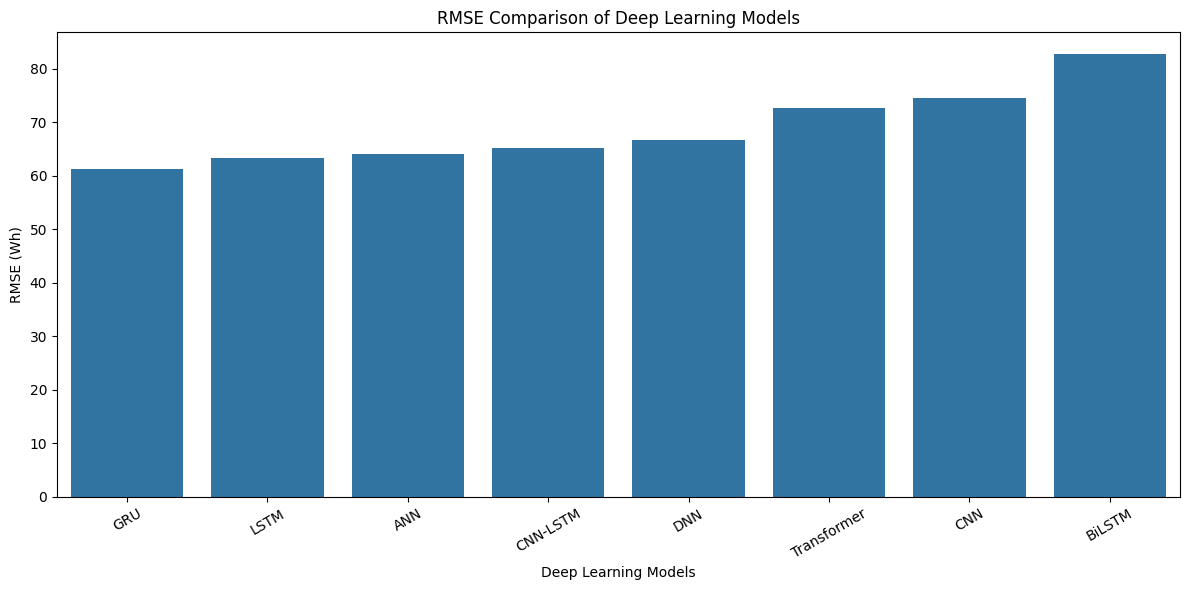

In [27]:
#Regression comparison graph

plt.figure(figsize=(12, 6))

sns.barplot(
    data=regression_df,
    x="Model",
    y="RMSE"
)

plt.title(
    "RMSE Comparison of Deep Learning Models"
)

plt.xlabel("Deep Learning Models")

plt.ylabel("RMSE (Wh)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

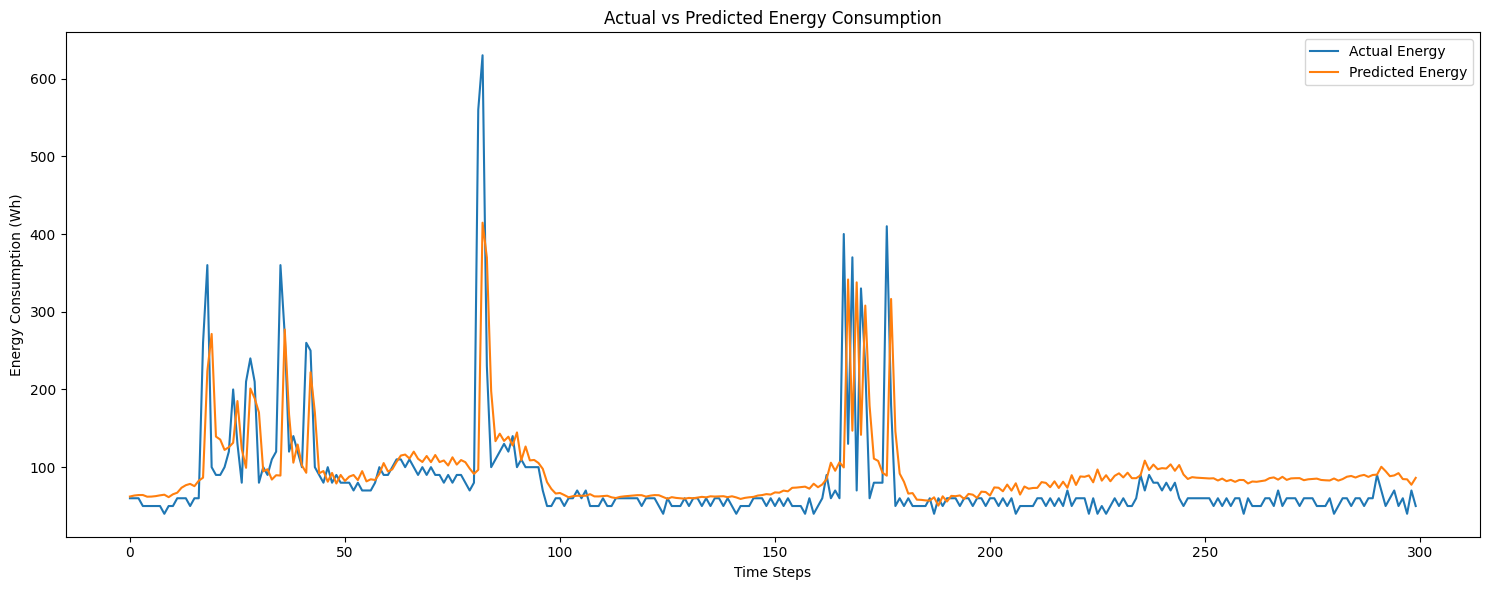

Best Regression Model: GRU


In [28]:
#Actual vs Predicted graph

# Select best model based on test RMSE

best_regression_name = (
    regression_df.iloc[0]["Model"]
)

best_model = trained_models[
    best_regression_name
]

# Predict using best model
pred_scaled = best_model.predict(
    X_test,
    verbose=0
)

predictions = y_scaler.inverse_transform(
    pred_scaled
).flatten()

# Plot actual vs predicted
plt.figure(figsize=(15, 6))

plt.plot(
    actual[:300],
    label="Actual Energy"
)

plt.plot(
    predictions[:300],
    label="Predicted Energy"
)

plt.title(
    "Actual vs Predicted Energy Consumption"
)

plt.xlabel("Time Steps")

plt.ylabel("Energy Consumption (Wh)")

plt.legend()

plt.tight_layout()

plt.show()

print("Best Regression Model:", best_regression_name)

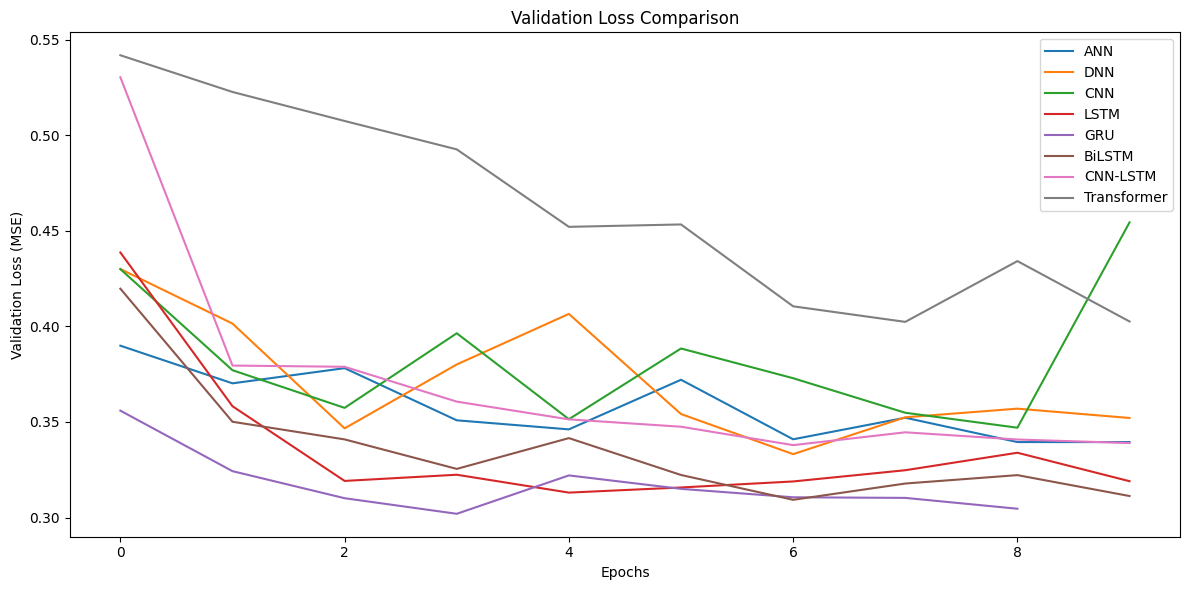

In [29]:
#Training and validation loss

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history['val_loss'],
        label=name
    )

plt.title(
    "Validation Loss Comparison"
)

plt.xlabel("Epochs")

plt.ylabel("Validation Loss (MSE)")

plt.legend()

plt.tight_layout()

plt.show()

In [30]:
#Save all eight models and results

import os
import joblib

save_path = (
    "/content/drive/MyDrive/Energy_Project"
)

os.makedirs(
    save_path,
    exist_ok=True
)

# Save all trained models
for name, model in trained_models.items():

    model.save(
        os.path.join(
            save_path,
            name + ".keras"
        )
    )

# Save scalers
joblib.dump(
    x_scaler,
    os.path.join(
        save_path,
        "x_scaler.pkl"
    )
)

joblib.dump(
    y_scaler,
    os.path.join(
        save_path,
        "y_scaler.pkl"
    )
)

# Save regression results
regression_df.to_csv(
    os.path.join(
        save_path,
        "regression_results.csv"
    ),
    index=False
)

# Save baseline results
baseline_df = pd.DataFrame([{
    "Model": "Persistence Baseline",
    "MAE": baseline_mae,
    "MSE": baseline_mse,
    "RMSE": baseline_rmse,
    "R2 Score": baseline_r2
}])

baseline_df.to_csv(
    os.path.join(
        save_path,
        "baseline_results.csv"
    ),
    index=False
)

print("All models and results saved successfully!")

All models and results saved successfully!


In [31]:
#Display final project results

print("========== FINAL PROJECT RESULTS ==========")

print("\nBest Regression Model:")

print(best_regression_name)

print("\nRegression Results:")

display(
    regression_df.round(4)
)

print("\nPersistence Baseline Results:")

display(
    baseline_df.round(4)
)

print("\nProject completed successfully!")

========== FINAL PROJECT RESULTS ==========

Best Regression Model:
GRU

Regression Results:


,Model,MAE,MSE,RMSE,R2 Score
0,GRU,33.5611,3755.3199,61.2807,0.5452
1,LSTM,34.4913,4016.4899,63.3758,0.5136
2,ANN,27.7968,4104.3525,64.0652,0.5030
3,CNN-LSTM,32.6934,4256.4119,65.2412,0.4846
4,DNN,42.2476,4445.3076,66.6731,0.4617
5,Transformer,37.4636,5264.2535,72.5552,0.3625
6,CNN,37.1886,5542.7952,74.4500,0.3288
7,BiLSTM,55.3106,6828.2176,82.6330,0.1731



Persistence Baseline Results:


,Model,MAE,MSE,RMSE,R2 Score
0,Persistence Baseline,26.7376,4467.1733,66.8369,0.459



Project completed successfully!
